# Tugas 2: Pengambilan Data Citra Satelit Sentinel-2A
## Pemetaan & Klasifikasi Lahan: Sawah vs Bukan Sawah (Pemukiman)

Notebook ini bertujuan untuk melakukan **crawling dan ekstraksi citra satelit Sentinel-2A (Level-2A BOA Reflectance)** dari Copernicus Data Space Ecosystem (CDSE) openEO API berdasarkan **50 titik/poligon sawah** dan **50 titik/poligon bukan sawah (pemukiman)**.

### Rincian Alur Pengambilan Data:
1. **Inisialisasi GeoJSON**: Memuat 50 poligon sawah dan 50 poligon bukan sawah dari hasil penandaan geojson.io.
2. **Ekspor Data Spasial**: Menyimpan ke format `.geojson` dan file koordinat tabular `.csv` di folder `data/`.
3. **Autentikasi CDSE openEO**: Menggunakan kredensial OIDC dari file `.env`.
4. **Pengunduhan Citra Sentinel-2A (.tif)**: Mengunduh citra beresolusi tinggi 10 meter untuk band optik (`B02_Blue`, `B03_Green`, `B04_Red`, `B08_NIR`) dengan filter tutupan awan rendah.
5. **Ekstraksi Patch .tif & Dataset Spektral**: Menyimpan 100 file patch `.tif` individual dan mengekstrak indeks vegetasi (NDVI & NDWI) ke dalam file CSV `data/dataset_citra_sentinel2_100.csv`.

--- 
### Sel 1: Inisialisasi Koordinat GeoJSON (50 Sawah & 50 Bukan Sawah)

In [1]:
import json

geojson_sawah_raw = """
{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4350137,
              -7.2420976
            ],
            [
              111.4349877,
              -7.242356
            ],
            [
              111.4355933,
              -7.2424335
            ],
            [
              111.4355282,
              -7.2423786
            ],
            [
              111.4356161,
              -7.2423754
            ],
            [
              111.4355933,
              -7.2423011
            ],
            [
              111.4356617,
              -7.2422526
            ],
            [
              111.4356324,
              -7.2421492
            ],
            [
              111.4350137,
              -7.2420976
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4342453,
              -7.2413062
            ],
            [
              111.4344309,
              -7.2416001
            ],
            [
              111.4343592,
              -7.2416227
            ],
            [
              111.4343625,
              -7.2416744
            ],
            [
              111.4346588,
              -7.2417455
            ],
            [
              111.4346653,
              -7.2414612
            ],
            [
              111.4342453,
              -7.2413062
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4353376,
              -7.2415604
            ],
            [
              111.4353376,
              -7.2416651
            ],
            [
              111.4357979,
              -7.2417524
            ],
            [
              111.4358214,
              -7.2416593
            ],
            [
              111.4353376,
              -7.2415604
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4342764,
              -7.2408743
            ],
            [
              111.4342558,
              -7.2409412
            ],
            [
              111.4343145,
              -7.241011
            ],
            [
              111.4343086,
              -7.2410605
            ],
            [
              111.4347015,
              -7.2412146
            ],
            [
              111.4346839,
              -7.2409936
            ],
            [
              111.4342764,
              -7.2408743
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4350826,
              -7.2406708
            ],
            [
              111.4352497,
              -7.2407347
            ],
            [
              111.4355077,
              -7.2409616
            ],
            [
              111.4354608,
              -7.2410198
            ],
            [
              111.4350796,
              -7.240854
            ],
            [
              111.4350826,
              -7.2406708
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4365045,
              -7.2410983
            ],
            [
              111.4363696,
              -7.2412815
            ],
            [
              111.4362259,
              -7.2413542
            ],
            [
              111.4363637,
              -7.2415374
            ],
            [
              111.4367478,
              -7.2415403
            ],
            [
              111.4367859,
              -7.2412553
            ],
            [
              111.4365045,
              -7.2410983
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4365103,
              -7.239704
            ],
            [
              111.4368592,
              -7.2398582
            ],
            [
              111.4367976,
              -7.2399832
            ],
            [
              111.4364605,
              -7.2398233
            ],
            [
              111.4365103,
              -7.239704
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.434314,
              -7.2395766
            ],
            [
              111.4345408,
              -7.2396151
            ],
            [
              111.4347935,
              -7.2396987
            ],
            [
              111.4347222,
              -7.239898
            ],
            [
              111.4342427,
              -7.2397823
            ],
            [
              111.434314,
              -7.2395766
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.438662,
              -7.2397309
            ],
            [
              111.4385324,
              -7.2399044
            ],
            [
              111.4383315,
              -7.239988
            ],
            [
              111.4385,
              -7.2401808
            ],
            [
              111.4387851,
              -7.2402323
            ],
            [
              111.4388629,
              -7.239898
            ],
            [
              111.438662,
              -7.2397309
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4355192,
              -7.2390173
            ],
            [
              111.4358368,
              -7.2390495
            ],
            [
              111.4357525,
              -7.2393709
            ],
            [
              111.4359145,
              -7.2395059
            ],
            [
              111.4358238,
              -7.2396923
            ],
            [
              111.4354091,
              -7.2394673
            ],
            [
              111.4355192,
              -7.2390173
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5191191,
              -7.1611385
            ],
            [
              111.5191297,
              -7.161321
            ],
            [
              111.519287,
              -7.1612999
            ],
            [
              111.5193936,
              -7.1612417
            ],
            [
              111.5193803,
              -7.1611465
            ],
            [
              111.5191191,
              -7.1611385
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5203825,
              -7.1614771
            ],
            [
              111.5201933,
              -7.1614903
            ],
            [
              111.5201266,
              -7.1616014
            ],
            [
              111.5201506,
              -7.1617812
            ],
            [
              111.5203772,
              -7.1617865
            ],
            [
              111.5203825,
              -7.1614771
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5203126,
              -7.1627796
            ],
            [
              111.5205659,
              -7.1627425
            ],
            [
              111.5205792,
              -7.1628695
            ],
            [
              111.5205419,
              -7.1629065
            ],
            [
              111.5204619,
              -7.1629171
            ],
            [
              111.520334,
              -7.1629091
            ],
            [
              111.5203126,
              -7.1627796
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5233855,
              -7.1626532
            ],
            [
              111.5232443,
              -7.1626743
            ],
            [
              111.5232896,
              -7.1629388
            ],
            [
              111.5233989,
              -7.1629415
            ],
            [
              111.5234389,
              -7.1628568
            ],
            [
              111.5235295,
              -7.162841
            ],
            [
              111.5234895,
              -7.162751
            ],
            [
              111.5233855,
              -7.1626532
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5225001,
              -7.1645374
            ],
            [
              111.5224814,
              -7.1648203
            ],
            [
              111.5229319,
              -7.1648865
            ],
            [
              111.5229346,
              -7.1645453
            ],
            [
              111.5225001,
              -7.1645374
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.523323,
              -7.1668661
            ],
            [
              111.5231243,
              -7.1669055
            ],
            [
              111.5230095,
              -7.1670719
            ],
            [
              111.5229874,
              -7.1673391
            ],
            [
              111.5231287,
              -7.1673435
            ],
            [
              111.523142,
              -7.1670807
            ],
            [
              111.5231905,
              -7.167015
            ],
            [
              111.5233185,
              -7.1670019
            ],
            [
              111.523323,
              -7.1668661
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5243384,
              -7.1673304
            ],
            [
              111.524515,
              -7.1674487
            ],
            [
              111.5246562,
              -7.1674618
            ],
            [
              111.5248593,
              -7.1673172
            ],
            [
              111.5248063,
              -7.1672034
            ],
            [
              111.5246871,
              -7.1673085
            ],
            [
              111.5246253,
              -7.1673129
            ],
            [
              111.5245061,
              -7.1672822
            ],
            [
              111.5243869,
              -7.1672296
            ],
            [
              111.5243384,
              -7.1673304
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5258924,
              -7.1657666
            ],
            [
              111.5258394,
              -7.1659637
            ],
            [
              111.5265811,
              -7.1661696
            ],
            [
              111.526612,
              -7.1660119
            ],
            [
              111.5264972,
              -7.1659988
            ],
            [
              111.5263074,
              -7.1659287
            ],
            [
              111.5261175,
              -7.1658717
            ],
            [
              111.5258924,
              -7.1657666
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5251957,
              -7.1638493
            ],
            [
              111.5255577,
              -7.1637048
            ],
            [
              111.5255533,
              -7.1636347
            ],
            [
              111.5262332,
              -7.163569
            ],
            [
              111.526348,
              -7.1638055
            ],
            [
              111.5263436,
              -7.1639632
            ],
            [
              111.526295,
              -7.163972
            ],
            [
              111.5262862,
              -7.1640026
            ],
            [
              111.5252178,
              -7.1640202
            ],
            [
              111.5251957,
              -7.1638493
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.518767,
              -7.1646348
            ],
            [
              111.5187303,
              -7.1648272
            ],
            [
              111.5194692,
              -7.1648843
            ],
            [
              111.5194482,
              -7.164718
            ],
            [
              111.518767,
              -7.1646348
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3880296,
              -7.1796289
            ],
            [
              111.3879943,
              -7.1796832
            ],
            [
              111.3880715,
              -7.1798428
            ],
            [
              111.3880586,
              -7.1799322
            ],
            [
              111.3879878,
              -7.1801173
            ],
            [
              111.3880136,
              -7.1802195
            ],
            [
              111.388139,
              -7.1802131
            ],
            [
              111.3882323,
              -7.1802737
            ],
            [
              111.3882388,
              -7.1801492
            ],
            [
              111.388139,
              -7.1799322
            ],
            [
              111.3881455,
              -7.1798556
            ],
            [
              111.3880296,
              -7.1796289
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3878624,
              -7.1796992
            ],
            [
              111.3877144,
              -7.179862
            ],
            [
              111.3876307,
              -7.1799066
            ],
            [
              111.3875471,
              -7.1799194
            ],
            [
              111.3872125,
              -7.1802865
            ],
            [
              111.3871385,
              -7.1803056
            ],
            [
              111.3870902,
              -7.1803663
            ],
            [
              111.3871063,
              -7.1804684
            ],
            [
              111.3873412,
              -7.1806057
            ],
            [
              111.3874216,
              -7.180577
            ],
            [
              111.387428,
              -7.1804684
            ],
            [
              111.3873444,
              -7.1803216
            ],
            [
              111.3873669,
              -7.1801748
            ],
            [
              111.3877079,
              -7.1799833
            ],
            [
              111.3878109,
              -7.1799928
            ],
            [
              111.3879717,
              -7.179846
            ],
            [
              111.3879106,
              -7.1797439
            ],
            [
              111.3878624,
              -7.1796992
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3866128,
              -7.1801614
            ],
            [
              111.3866836,
              -7.180238
            ],
            [
              111.3865871,
              -7.180305
            ],
            [
              111.3864905,
              -7.1803657
            ],
            [
              111.3864358,
              -7.1804231
            ],
            [
              111.3864712,
              -7.1804966
            ],
            [
              111.386542,
              -7.180621
            ],
            [
              111.3864294,
              -7.1806785
            ],
            [
              111.3863715,
              -7.1804327
            ],
            [
              111.3864584,
              -7.1803306
            ],
            [
              111.3865581,
              -7.1802348
            ],
            [
              111.3866128,
              -7.1801614
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3854467,
              -7.1809789
            ],
            [
              111.385408,
              -7.1810842
            ],
            [
              111.3853373,
              -7.1812151
            ],
            [
              111.3854917,
              -7.1812566
            ],
            [
              111.3856783,
              -7.1813683
            ],
            [
              111.3857426,
              -7.1813587
            ],
            [
              111.3857909,
              -7.1811257
            ],
            [
              111.3854467,
              -7.1809789
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3853211,
              -7.1793113
            ],
            [
              111.3854305,
              -7.1793464
            ],
            [
              111.3854305,
              -7.1796369
            ],
            [
              111.3852857,
              -7.1795986
            ],
            [
              111.3853275,
              -7.1794422
            ],
            [
              111.3853211,
              -7.1793113
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3871414,
              -7.1816499
            ],
            [
              111.3874728,
              -7.181902
            ],
            [
              111.3874278,
              -7.1820776
            ],
            [
              111.3873345,
              -7.1820808
            ],
            [
              111.3873184,
              -7.1821063
            ],
            [
              111.3872573,
              -7.181985
            ],
            [
              111.3872347,
              -7.1818318
            ],
            [
              111.3871318,
              -7.1816914
            ],
            [
              111.3871414,
              -7.1816499
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3838145,
              -7.1786801
            ],
            [
              111.3837225,
              -7.1791874
            ],
            [
              111.3840088,
              -7.1793142
            ],
            [
              111.3840804,
              -7.1787511
            ],
            [
              111.3838145,
              -7.1786801
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3860845,
              -7.1782185
            ],
            [
              111.3859107,
              -7.1783453
            ],
            [
              111.3859158,
              -7.178533
            ],
            [
              111.3862481,
              -7.1786852
            ],
            [
              111.3865344,
              -7.1786953
            ],
            [
              111.3868259,
              -7.1786192
            ],
            [
              111.3870917,
              -7.1784518
            ],
            [
              111.3867236,
              -7.178396
            ],
            [
              111.3860845,
              -7.1782185
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3859427,
              -7.1772534
            ],
            [
              111.3859273,
              -7.1775121
            ],
            [
              111.3861932,
              -7.1775831
            ],
            [
              111.3862443,
              -7.1772788
            ],
            [
              111.3859427,
              -7.1772534
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3806152,
              -7.1781061
            ],
            [
              111.3806065,
              -7.1782447
            ],
            [
              111.3808335,
              -7.1784439
            ],
            [
              111.3811304,
              -7.1786605
            ],
            [
              111.3811304,
              -7.1787385
            ],
            [
              111.3812963,
              -7.1788165
            ],
            [
              111.3813138,
              -7.1789464
            ],
            [
              111.3815932,
              -7.1790417
            ],
            [
              111.3817154,
              -7.179111
            ],
            [
              111.3816368,
              -7.1792669
            ],
            [
              111.3820298,
              -7.1794229
            ],
            [
              111.3819599,
              -7.1791976
            ],
            [
              111.3817853,
              -7.1786692
            ],
            [
              111.3812614,
              -7.1784959
            ],
            [
              111.3812527,
              -7.1783486
            ],
            [
              111.3806152,
              -7.1781061
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3453556,
              -7.0315426
            ],
            [
              111.345192,
              -7.0322736
            ],
            [
              111.3450849,
              -7.0324111
            ],
            [
              111.3461677,
              -7.0327235
            ],
            [
              111.3465266,
              -7.0318863
            ],
            [
              111.3453556,
              -7.0315426
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.34657063084364,
              -7.030449246195104
            ],
            [
              111.34656433557927,
              -7.030449246195104
            ],
            [
              111.34656433557927,
              -7.0304554941283754
            ],
            [
              111.34657063084364,
              -7.0304554941283754
            ],
            [
              111.3464888,
              -7.0307242
            ],
            [
              111.3466902,
              -7.0307679
            ],
            [
              111.3469987,
              -7.0306679
            ],
            [
              111.3469483,
              -7.0304805
            ],
            [
              111.34657063084364,
              -7.030449246195104
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3430263,
              -7.0295259
            ],
            [
              111.3430515,
              -7.0297946
            ],
            [
              111.3436999,
              -7.0301382
            ],
            [
              111.3437503,
              -7.029957
            ],
            [
              111.3436369,
              -7.0298133
            ],
            [
              111.343297,
              -7.0295884
            ],
            [
              111.3430263,
              -7.0295259
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3404363,
              -7.0308106
            ],
            [
              111.3403719,
              -7.0311018
            ],
            [
              111.3403505,
              -7.0314711
            ],
            [
              111.3407297,
              -7.0315208
            ],
            [
              111.3408085,
              -7.0308674
            ],
            [
              111.3404363,
              -7.0308106
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3382667,
              -7.0339121
            ],
            [
              111.3383884,
              -7.0340541
            ],
            [
              111.3383884,
              -7.0342317
            ],
            [
              111.3386675,
              -7.0344021
            ],
            [
              111.3389895,
              -7.0343808
            ],
            [
              111.339011,
              -7.0340825
            ],
            [
              111.3385887,
              -7.0340328
            ],
            [
              111.3382667,
              -7.0339121
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3429587,
              -7.0366755
            ],
            [
              111.3429873,
              -7.0369099
            ],
            [
              111.3431662,
              -7.0369525
            ],
            [
              111.3431376,
              -7.0373147
            ],
            [
              111.3432234,
              -7.0373361
            ],
            [
              111.3433308,
              -7.0367395
            ],
            [
              111.3429587,
              -7.0366755
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3393093,
              -7.0369786
            ],
            [
              111.3392378,
              -7.0373834
            ],
            [
              111.3395097,
              -7.0373337
            ],
            [
              111.3395526,
              -7.0370851
            ],
            [
              111.3393093,
              -7.0369786
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.336027,
              -7.0356664
            ],
            [
              111.3364564,
              -7.0357729
            ],
            [
              111.3363992,
              -7.0361351
            ],
            [
              111.3359841,
              -7.0359931
            ],
            [
              111.336027,
              -7.0356664
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3407769,
              -7.0290466
            ],
            [
              111.340736,
              -7.0295477
            ],
            [
              111.3406677,
              -7.0296966
            ],
            [
              111.3406541,
              -7.029954
            ],
            [
              111.3408315,
              -7.0299946
            ],
            [
              111.3410498,
              -7.0295883
            ],
            [
              111.3413091,
              -7.0292226
            ],
            [
              111.3412954,
              -7.0290195
            ],
            [
              111.3407769,
              -7.0290466
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3376596,
              -7.031056
            ],
            [
              111.3376187,
              -7.0314081
            ],
            [
              111.3379598,
              -7.0314488
            ],
            [
              111.3380144,
              -7.030731
            ],
            [
              111.3376596,
              -7.031056
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.237957,
              -7.0466723
            ],
            [
              111.2379289,
              -7.0472083
            ],
            [
              111.2380808,
              -7.0472362
            ],
            [
              111.2382383,
              -7.0473535
            ],
            [
              111.2384521,
              -7.0473926
            ],
            [
              111.238801,
              -7.04732
            ],
            [
              111.2387222,
              -7.0470799
            ],
            [
              111.2385084,
              -7.0470017
            ],
            [
              111.2381258,
              -7.0466835
            ],
            [
              111.237957,
              -7.0466723
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2361511,
              -7.0477723
            ],
            [
              111.2361229,
              -7.0479733
            ],
            [
              111.2363873,
              -7.0480905
            ],
            [
              111.2366236,
              -7.0481687
            ],
            [
              111.2369612,
              -7.0482134
            ],
            [
              111.236995,
              -7.0479509
            ],
            [
              111.2361511,
              -7.0477723
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2356827,
              -7.0532913
            ],
            [
              111.2355364,
              -7.0534476
            ],
            [
              111.2354689,
              -7.0537324
            ],
            [
              111.2353901,
              -7.0542181
            ],
            [
              111.2356939,
              -7.0542237
            ],
            [
              111.2358008,
              -7.0539724
            ],
            [
              111.2359809,
              -7.0539724
            ],
            [
              111.2361496,
              -7.0536486
            ],
            [
              111.236234,
              -7.0533806
            ],
            [
              111.2356827,
              -7.0532913
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2383048,
              -7.0549521
            ],
            [
              111.2383161,
              -7.0552647
            ],
            [
              111.2382035,
              -7.0554546
            ],
            [
              111.2384736,
              -7.0556165
            ],
            [
              111.2386311,
              -7.0554713
            ],
            [
              111.2386705,
              -7.0551363
            ],
            [
              111.2383048,
              -7.0549521
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2363357,
              -7.0555383
            ],
            [
              111.2360544,
              -7.0565266
            ],
            [
              111.236195,
              -7.0565601
            ],
            [
              111.2364482,
              -7.055583
            ],
            [
              111.2363357,
              -7.0555383
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2339552,
              -7.0546432
            ],
            [
              111.2335928,
              -7.0562452
            ],
            [
              111.2339113,
              -7.0562343
            ],
            [
              111.234054,
              -7.055733
            ],
            [
              111.2340979,
              -7.0551663
            ],
            [
              111.2342407,
              -7.0547195
            ],
            [
              111.2339552,
              -7.0546432
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2321334,
              -7.0492781
            ],
            [
              111.2321554,
              -7.0493543
            ],
            [
              111.2318699,
              -7.0503461
            ],
            [
              111.2323531,
              -7.0504878
            ],
            [
              111.232408,
              -7.0501499
            ],
            [
              111.2323311,
              -7.0499211
            ],
            [
              111.2325288,
              -7.0493543
            ],
            [
              111.2321334,
              -7.0492781
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.23005,
              -7.0530589
            ],
            [
              111.2303023,
              -7.0531456
            ],
            [
              111.2302635,
              -7.0534345
            ],
            [
              111.2302829,
              -7.0535693
            ],
            [
              111.2301664,
              -7.0536464
            ],
            [
              111.23005,
              -7.0536078
            ],
            [
              111.23005,
              -7.0530589
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2329075,
              -7.0469715
            ],
            [
              111.2328881,
              -7.047299
            ],
            [
              111.233383,
              -7.0474434
            ],
            [
              111.2337226,
              -7.0472797
            ],
            [
              111.2338779,
              -7.0471256
            ],
            [
              111.2329075,
              -7.0469715
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.2306666,
              -7.05628
            ],
            [
              111.2307151,
              -7.0564822
            ],
            [
              111.2314914,
              -7.0564629
            ],
            [
              111.2315399,
              -7.0561933
            ],
            [
              111.2306666,
              -7.05628
            ]
          ]
        ]
      }
    }
  ]
}



"""

geojson_bukan_sawah_raw = """

{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.443082,
              -7.2372738
            ],
            [
              111.443044,
              -7.2373781
            ],
            [
              111.4431567,
              -7.2374221
            ],
            [
              111.4431922,
              -7.2373165
            ],
            [
              111.443082,
              -7.2372738
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4440142,
              -7.2368758
            ],
            [
              111.443942,
              -7.237055
            ],
            [
              111.4440046,
              -7.2370837
            ],
            [
              111.4440793,
              -7.2369093
            ],
            [
              111.4440142,
              -7.2368758
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4426784,
              -7.2366055
            ],
            [
              111.4426254,
              -7.2367082
            ],
            [
              111.4427241,
              -7.2367321
            ],
            [
              111.4427795,
              -7.2366341
            ],
            [
              111.4426784,
              -7.2366055
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4415622,
              -7.2373959
            ],
            [
              111.4415286,
              -7.2375959
            ],
            [
              111.4416115,
              -7.2376092
            ],
            [
              111.4416194,
              -7.2375803
            ],
            [
              111.4417113,
              -7.2375981
            ],
            [
              111.4417314,
              -7.2374715
            ],
            [
              111.441662,
              -7.2374248
            ],
            [
              111.4415622,
              -7.2373959
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4425409,
              -7.236981
            ],
            [
              111.4426212,
              -7.2370158
            ],
            [
              111.4425509,
              -7.2371777
            ],
            [
              111.4424806,
              -7.2371429
            ],
            [
              111.4425409,
              -7.236981
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4413444,
              -7.2370612
            ],
            [
              111.4413091,
              -7.2372117
            ],
            [
              111.4413974,
              -7.2372362
            ],
            [
              111.4414433,
              -7.2370962
            ],
            [
              111.4413444,
              -7.2370612
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.44086,
              -7.2371945
            ],
            [
              111.4408212,
              -7.2374046
            ],
            [
              111.4409694,
              -7.2374676
            ],
            [
              111.4410506,
              -7.2372505
            ],
            [
              111.44086,
              -7.2371945
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4407527,
              -7.2362926
            ],
            [
              111.4407316,
              -7.2364782
            ],
            [
              111.4408233,
              -7.2365132
            ],
            [
              111.4408798,
              -7.2363276
            ],
            [
              111.4407527,
              -7.2362926
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4400042,
              -7.2369983
            ],
            [
              111.4399752,
              -7.2371134
            ],
            [
              111.4400913,
              -7.2371614
            ],
            [
              111.44013,
              -7.2370271
            ],
            [
              111.4400042,
              -7.2369983
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4383209,
              -7.2350486
            ],
            [
              111.4382919,
              -7.2351733
            ],
            [
              111.4384177,
              -7.2352309
            ],
            [
              111.438437,
              -7.2351062
            ],
            [
              111.4383209,
              -7.2350486
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3138127,
              -7.0034599
            ],
            [
              111.3143554,
              -7.0042403
            ],
            [
              111.314898,
              -7.0038886
            ],
            [
              111.3144883,
              -7.0031851
            ],
            [
              111.3138127,
              -7.0034599
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3132656,
              -7.006115
            ],
            [
              111.3131006,
              -7.0062624
            ],
            [
              111.3131053,
              -7.0064075
            ],
            [
              111.3132019,
              -7.0064379
            ],
            [
              111.3132962,
              -7.0063747
            ],
            [
              111.3133481,
              -7.0061969
            ],
            [
              111.3133575,
              -7.006129
            ],
            [
              111.3132656,
              -7.006115
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3119316,
              -7.0059015
            ],
            [
              111.3119344,
              -7.006033
            ],
            [
              111.3120979,
              -7.0060582
            ],
            [
              111.3120923,
              -7.0059155
            ],
            [
              111.3119316,
              -7.0059015
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3133549,
              -7.001222
            ],
            [
              111.3133448,
              -7.0013573
            ],
            [
              111.3135316,
              -7.0014125
            ],
            [
              111.3135417,
              -7.0012671
            ],
            [
              111.3133549,
              -7.001222
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3120146,
              -7.0027227
            ],
            [
              111.3122418,
              -7.0027428
            ],
            [
              111.3121964,
              -7.0028731
            ],
            [
              111.3120247,
              -7.0028731
            ],
            [
              111.3120146,
              -7.0027227
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3100762,
              -7.007929
            ],
            [
              111.3105761,
              -7.0079792
            ],
            [
              111.310566,
              -7.0080694
            ],
            [
              111.3100762,
              -7.0080293
            ],
            [
              111.3100762,
              -7.007929
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3146004,
              -7.0044195
            ],
            [
              111.3146206,
              -7.0046451
            ],
            [
              111.3146711,
              -7.0047854
            ],
            [
              111.314762,
              -7.0048054
            ],
            [
              111.3149842,
              -7.0047052
            ],
            [
              111.3148176,
              -7.0043594
            ],
            [
              111.3146004,
              -7.0044195
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3132084,
              -7.0044407
            ],
            [
              111.3136275,
              -7.0044557
            ],
            [
              111.3137336,
              -7.0047213
            ],
            [
              111.3133145,
              -7.0049218
            ],
            [
              111.3132084,
              -7.0046863
            ],
            [
              111.3132084,
              -7.0044407
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3166214,
              -7.0019911
            ],
            [
              111.3165457,
              -7.0023169
            ],
            [
              111.3166871,
              -7.002377
            ],
            [
              111.3167931,
              -7.0020513
            ],
            [
              111.3166214,
              -7.0019911
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.3145208,
              -7.0015751
            ],
            [
              111.3144905,
              -7.0017606
            ],
            [
              111.3148238,
              -7.0018207
            ],
            [
              111.314844,
              -7.0016102
            ],
            [
              111.3145208,
              -7.0015751
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5815457,
              -7.1537844
            ],
            [
              111.5811166,
              -7.1540612
            ],
            [
              111.5817925,
              -7.154487
            ],
            [
              111.5818891,
              -7.1541144
            ],
            [
              111.5815457,
              -7.1537844
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5787884,
              -7.153497
            ],
            [
              111.5785309,
              -7.154636
            ],
            [
              111.579121,
              -7.154849
            ],
            [
              111.5793892,
              -7.1547531
            ],
            [
              111.5795716,
              -7.1538589
            ],
            [
              111.5787884,
              -7.153497
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5908856,
              -7.1541018
            ],
            [
              111.5912649,
              -7.1544444
            ],
            [
              111.5906522,
              -7.154869
            ],
            [
              111.5903507,
              -7.154565
            ],
            [
              111.5908856,
              -7.1541018
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5982646,
              -7.1511847
            ],
            [
              111.6000002,
              -7.1510429
            ],
            [
              111.6001431,
              -7.1514279
            ],
            [
              111.5983667,
              -7.1515494
            ],
            [
              111.5982646,
              -7.1511847
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5903364,
              -7.1487463
            ],
            [
              111.5918473,
              -7.1483006
            ],
            [
              111.5922965,
              -7.1491717
            ],
            [
              111.590806,
              -7.1497187
            ],
            [
              111.5903364,
              -7.1487463
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5863534,
              -7.1506719
            ],
            [
              111.5865544,
              -7.1509965
            ],
            [
              111.5853878,
              -7.1516026
            ],
            [
              111.5850883,
              -7.1514305
            ],
            [
              111.5850134,
              -7.1512702
            ],
            [
              111.5852262,
              -7.1511333
            ],
            [
              111.5851434,
              -7.1510043
            ],
            [
              111.5850252,
              -7.1510551
            ],
            [
              111.5849464,
              -7.1508479
            ],
            [
              111.5848754,
              -7.1506875
            ],
            [
              111.5846045,
              -7.1504529
            ],
            [
              111.5843909,
              -7.1504105
            ],
            [
              111.5843838,
              -7.1500432
            ],
            [
              111.5845191,
              -7.1499867
            ],
            [
              111.5846259,
              -7.1496194
            ],
            [
              111.5855087,
              -7.1496829
            ],
            [
              111.5854019,
              -7.1500361
            ],
            [
              111.585409,
              -7.1502904
            ],
            [
              111.585765,
              -7.1502834
            ],
            [
              111.5860213,
              -7.15046
            ],
            [
              111.5861922,
              -7.1506578
            ],
            [
              111.5863534,
              -7.1506719
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5977923,
              -7.135229
            ],
            [
              111.59875,
              -7.1357276
            ],
            [
              111.5990954,
              -7.1338581
            ],
            [
              111.5992838,
              -7.1336711
            ],
            [
              111.6003986,
              -7.1339983
            ],
            [
              111.6008696,
              -7.1347772
            ],
            [
              111.6007126,
              -7.1361014
            ],
            [
              111.6009481,
              -7.1364442
            ],
            [
              111.6015604,
              -7.1367558
            ],
            [
              111.6012778,
              -7.1377528
            ],
            [
              111.6004928,
              -7.137488
            ],
            [
              111.599959,
              -7.1385629
            ],
            [
              111.6008539,
              -7.1389835
            ],
            [
              111.6004614,
              -7.1396378
            ],
            [
              111.5992681,
              -7.1393107
            ],
            [
              111.597965,
              -7.1390147
            ],
            [
              111.5978865,
              -7.1387187
            ],
            [
              111.5967404,
              -7.1384071
            ],
            [
              111.5977923,
              -7.135229
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5921258,
              -7.1503079
            ],
            [
              111.5921843,
              -7.150966
            ],
            [
              111.5930687,
              -7.1510499
            ],
            [
              111.5929321,
              -7.1503337
            ],
            [
              111.5921258,
              -7.1503079
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5837748,
              -7.1526039
            ],
            [
              111.5840956,
              -7.1530176
            ],
            [
              111.5836145,
              -7.1532085
            ],
            [
              111.5838711,
              -7.153601
            ],
            [
              111.5832296,
              -7.153845
            ],
            [
              111.5830692,
              -7.1534207
            ],
            [
              111.5835289,
              -7.153251
            ],
            [
              111.5834327,
              -7.1529221
            ],
            [
              111.5837748,
              -7.1526039
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.5886405,
              -7.1601159
            ],
            [
              111.5886654,
              -7.1602971
            ],
            [
              111.5891469,
              -7.1603795
            ],
            [
              111.5891635,
              -7.1601983
            ],
            [
              111.5886405,
              -7.1601159
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4126991,
              -6.9686929
            ],
            [
              111.4125378,
              -6.9693753
            ],
            [
              111.4133165,
              -6.9695982
            ],
            [
              111.413555,
              -6.9689158
            ],
            [
              111.4126991,
              -6.9686929
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4139966,
              -6.9687136
            ],
            [
              111.4138704,
              -6.9692428
            ],
            [
              111.414144,
              -6.9693194
            ],
            [
              111.4142422,
              -6.9687902
            ],
            [
              111.4139966,
              -6.9687136
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4132335,
              -6.9672896
            ],
            [
              111.4131493,
              -6.9676656
            ],
            [
              111.4131213,
              -6.9678606
            ],
            [
              111.4134369,
              -6.967972
            ],
            [
              111.4135352,
              -6.967401
            ],
            [
              111.4132335,
              -6.9672896
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4149531,
              -6.9721552
            ],
            [
              111.415332,
              -6.9722527
            ],
            [
              111.4153179,
              -6.9724337
            ],
            [
              111.4149181,
              -6.9723502
            ],
            [
              111.4149531,
              -6.9721552
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4163593,
              -6.9689759
            ],
            [
              111.4167311,
              -6.9691778
            ],
            [
              111.4165627,
              -6.9695051
            ],
            [
              111.416226,
              -6.9692196
            ],
            [
              111.4163593,
              -6.9689759
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4200926,
              -6.9668463
            ],
            [
              111.4200224,
              -6.9673199
            ],
            [
              111.420738,
              -6.967494
            ],
            [
              111.4207871,
              -6.9670692
            ],
            [
              111.4200926,
              -6.9668463
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4218742,
              -6.9634612
            ],
            [
              111.422723,
              -6.9634821
            ],
            [
              111.42273,
              -6.9641575
            ],
            [
              111.4219022,
              -6.9641436
            ],
            [
              111.4218742,
              -6.9634612
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4288492,
              -6.9552828
            ],
            [
              111.4285896,
              -6.9562925
            ],
            [
              111.4295367,
              -6.9566616
            ],
            [
              111.4298243,
              -6.9554917
            ],
            [
              111.4288492,
              -6.9552828
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4225485,
              -6.9701671
            ],
            [
              111.4225588,
              -6.9708517
            ],
            [
              111.4231565,
              -6.9709458
            ],
            [
              111.4232389,
              -6.9705473
            ],
            [
              111.4228992,
              -6.9703429
            ],
            [
              111.4225485,
              -6.9701671
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4141887,
              -6.969573
            ],
            [
              111.4141429,
              -6.9698406
            ],
            [
              111.4142904,
              -6.9699113
            ],
            [
              111.4142599,
              -6.9700426
            ],
            [
              111.4145041,
              -6.9700729
            ],
            [
              111.4145549,
              -6.9699214
            ],
            [
              111.414677,
              -6.969977
            ],
            [
              111.4147584,
              -6.9696639
            ],
            [
              111.4141887,
              -6.969573
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4089865,
              -6.9738384
            ],
            [
              111.408894,
              -6.9742873
            ],
            [
              111.4091407,
              -6.9743588
            ],
            [
              111.4092538,
              -6.9739914
            ],
            [
              111.4089865,
              -6.9738384
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4083045,
              -6.976871
            ],
            [
              111.4085512,
              -6.9768812
            ],
            [
              111.4085923,
              -6.9772383
            ],
            [
              111.4083045,
              -6.9772485
            ],
            [
              111.4083045,
              -6.976871
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4103289,
              -6.9719955
            ],
            [
              111.4103494,
              -6.9721791
            ],
            [
              111.4107503,
              -6.9721995
            ],
            [
              111.410812,
              -6.9719955
            ],
            [
              111.4103289,
              -6.9719955
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4202648,
              -6.9699531
            ],
            [
              111.4202153,
              -6.9703467
            ],
            [
              111.4204731,
              -6.9704205
            ],
            [
              111.4205474,
              -6.9700417
            ],
            [
              111.4202648,
              -6.9699531
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4226578,
              -6.9643561
            ],
            [
              111.4231832,
              -6.9644841
            ],
            [
              111.4230543,
              -6.965109
            ],
            [
              111.4225388,
              -6.9649958
            ],
            [
              111.4226578,
              -6.9643561
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4112021,
              -6.9726804
            ],
            [
              111.4112566,
              -6.9730741
            ],
            [
              111.4113954,
              -6.9730593
            ],
            [
              111.4114351,
              -6.97271
            ],
            [
              111.4112021,
              -6.9726804
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4076745,
              -6.9716879
            ],
            [
              111.4078084,
              -6.9717863
            ],
            [
              111.407739,
              -6.9718651
            ],
            [
              111.4076398,
              -6.9718454
            ],
            [
              111.4076745,
              -6.9716879
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4069285,
              -6.9697093
            ],
            [
              111.4071318,
              -6.9697487
            ],
            [
              111.4070921,
              -6.96998
            ],
            [
              111.4068889,
              -6.9699554
            ],
            [
              111.4069285,
              -6.9697093
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4131256,
              -6.9649584
            ],
            [
              111.4130364,
              -6.9654406
            ],
            [
              111.4133784,
              -6.96548
            ],
            [
              111.4134379,
              -6.9649879
            ],
            [
              111.4131256,
              -6.9649584
            ]
          ]
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              111.4137991,
              -6.9661632
            ],
            [
              111.4137744,
              -6.9663797
            ],
            [
              111.4138685,
              -6.9663993
            ],
            [
              111.4139082,
              -6.9661828
            ],
            [
              111.4137991,
              -6.9661632
            ]
          ]
        ]
      }
    }
  ]
}




"""

--- 
### Sel 2: Parsing & Ekspor Data Spasial ke Folder `data/`

In [2]:
import os
import json
import pandas as pd
import geopandas as gpd

# 1. Tentukan direktori data
DATA_DIR = os.path.join(os.getcwd(), "data")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "sawah"), exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "bukan_sawah"), exist_ok=True)

# 2. Parse GeoJSON string
sawah_json = json.loads(geojson_sawah_raw)
bukan_json = json.loads(geojson_bukan_sawah_raw)

# Beri properti id dan kelas
for i, f in enumerate(sawah_json["features"]):
    f["properties"] = {"id": i + 1, "kelas": "sawah", "label": 1}

for i, f in enumerate(bukan_json["features"]):
    f["properties"] = {"id": i + 1, "kelas": "bukan_sawah", "label": 0}

# 3. Simpan file GeoJSON mandiri
with open(os.path.join(DATA_DIR, "sawah_50.geojson"), "w", encoding="utf-8") as f:
    json.dump(sawah_json, f, indent=2)

with open(os.path.join(DATA_DIR, "bukan_sawah_50.geojson"), "w", encoding="utf-8") as f:
    json.dump(bukan_json, f, indent=2)

all_features = sawah_json["features"] + bukan_json["features"]
all_geojson = {"type": "FeatureCollection", "features": all_features}
with open(os.path.join(DATA_DIR, "dataset_aoi_100.geojson"), "w", encoding="utf-8") as f:
    json.dump(all_geojson, f, indent=2)

# 4. Buat GeoDataFrame dan simpan CSV koordinat
gdf_all = gpd.GeoDataFrame.from_features(all_features, crs="EPSG:4326")
gdf_all["lon_centroid"] = gdf_all.geometry.centroid.x
gdf_all["lat_centroid"] = gdf_all.geometry.centroid.y

df_coords = gdf_all[["id", "kelas", "label", "lon_centroid", "lat_centroid"]].copy()
df_coords.to_csv(os.path.join(DATA_DIR, "koordinat_sampel_100.csv"), index=False)

print("=== STATUS EKSPOR DATA SPASIAL ===")
print(f"Total Sampel Sawah       : {len(sawah_json['features'])} poligon")
print(f"Total Sampel Bukan Sawah : {len(bukan_json['features'])} poligon")
print("File GeoJSON tersimpan   : data/sawah_50.geojson & data/bukan_sawah_50.geojson")
print("File Koordinat CSV       : data/koordinat_sampel_100.csv")
display(df_coords.head(10))


=== STATUS EKSPOR DATA SPASIAL ===
Total Sampel Sawah       : 50 poligon
Total Sampel Bukan Sawah : 50 poligon
File GeoJSON tersimpan   : data/sawah_50.geojson & data/bukan_sawah_50.geojson
File Koordinat CSV       : data/koordinat_sampel_100.csv


C:\Users\user\AppData\Local\Temp\ipykernel_16660\1529565819.py:37: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_all["lon_centroid"] = gdf_all.geometry.centroid.x
C:\Users\user\AppData\Local\Temp\ipykernel_16660\1529565819.py:38: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_all["lat_centroid"] = gdf_all.geometry.centroid.y


,id,kelas,label,lon_centroid,lat_centroid
0,1,sawah,1,111.435314,-7.242257
1,2,sawah,1,111.434499,-7.241540
2,3,sawah,1,111.435571,-7.241658
3,4,sawah,1,111.434495,-7.241035
4,5,sawah,1,111.435262,-7.240849
5,6,sawah,1,111.436539,-7.241358
6,7,sawah,1,111.436659,-7.239843
7,8,sawah,1,111.434518,-7.239734
8,9,sawah,1,111.438639,-7.240008
9,10,sawah,1,111.435654,-7.239339


--- 
### Sel 3: Setup Koneksi & Autentikasi openEO Copernicus CDSE

In [3]:
import openeo

# 1. Load kredensial dari file .env
env_file = os.path.join(os.getcwd(), ".env")
if os.path.exists(env_file):
    with open(env_file, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                k, v = line.split("=", 1)
                os.environ[k.strip()] = v.strip().strip('"').strip("'")

client_id = os.getenv("CDSE_CLIENT_ID")
client_secret = os.getenv("CDSE_CLIENT_SECRET")

# 2. Hubungkan ke CDSE openEO
print("Menghubungkan ke Copernicus Data Space Ecosystem (CDSE)...")
connection = openeo.connect("https://openeo.dataspace.copernicus.eu")

if client_id and client_secret:
    connection.authenticate_oidc_client_credentials(client_id=client_id, client_secret=client_secret)
    print("Status: BERHASIL TERAUTENTIKASI via OIDC Client Credentials!")
else:
    print("Kredensial .env belum ditemukan. Membuka login browser...")
    connection.authenticate_oidc()

print(f"Versi API openEO Backend: {connection.capabilities().api_version()}")


Menghubungkan ke Copernicus Data Space Ecosystem (CDSE)...

Status: BERHASIL TERAUTENTIKASI via OIDC Client Credentials!


Versi API openEO Backend: 1.2.0


--- 
### Sel 4: Pengunduhan Master Citra Satelit Sentinel-2A (.tif)

In [4]:
# 1. Hitung Bounding Box mencakup seluruh 100 titik sampel
bounds = gdf_all.total_bounds  # [minx, miny, maxx, maxy]
spatial_extent = {
    "west": float(bounds[0] - 0.01),
    "south": float(bounds[1] - 0.01),
    "east": float(bounds[2] + 0.01),
    "north": float(bounds[3] + 0.01),
    "crs": 4326
}

# 2. Parameter Sentinel-2A Level-2A
# Rentang waktu musim cerah (Juli 2024)
temporal_extent = ["2024-07-01", "2024-07-20"]
bands = ["B02", "B03", "B04", "B08"]  # Blue, Green, Red, NIR (Resolusi 10 meter)

master_tif_path = os.path.join(DATA_DIR, "sentinel2_master_aoi.tif")

print(f"Spatial Extent  : {spatial_extent}")
print(f"Temporal Extent : {temporal_extent}")
print(f"Bands           : {bands}")
print("\nMemuat koleksi SENTINEL2_L2A dari openEO CDSE...")

cube = connection.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=spatial_extent,
    temporal_extent=temporal_extent,
    bands=bands,
    properties={"eo:cloud_cover": lambda v: v <= 25}
)

# Reduksi temporal dengan median untuk bebas awan
cube_composite = cube.reduce_dimension(dimension="t", reducer="median")

# 3. Eksekusi unduhan master GeoTIFF (.tif)
if not os.path.exists(master_tif_path):
    print(f"Sedang mengunduh master GeoTIFF ke: {master_tif_path} ...")
    cube_composite.download(master_tif_path, format="GTiff")
    print(f"Master GeoTIFF berhasil diunduh! Ukuran: {os.path.getsize(master_tif_path) / (1024*1024):.2f} MB")
else:
    print(f"Master GeoTIFF sudah tersedia di: {master_tif_path} (Ukuran: {os.path.getsize(master_tif_path) / (1024*1024):.2f} MB)")


Spatial Extent  : {'west': 111.22005, 'south': -7.2524334999999995, 'east': 111.6115604, 'north': -6.9452828, 'crs': 4326}
Temporal Extent : ['2024-07-01', '2024-07-20']
Bands           : ['B02', 'B03', 'B04', 'B08']

Memuat koleksi SENTINEL2_L2A dari openEO CDSE...


Master GeoTIFF sudah tersedia di: d:\university\semester 5_book\proyek sain data\src\tugas-2\1-crawling\data\sentinel2_master_aoi.tif (Ukuran: 110.62 MB)


--- 
### Sel 5: Ekstraksi 100 Patch .tif Individual & Pembuatan Dataset Spektral

In [5]:
import numpy as np
import rasterio
from rasterio.mask import mask

# 1. Buka master TIF dan re-proyeksikan vektor GeoJSON ke CRS Raster
with rasterio.open(master_tif_path) as src:
    raster_crs = src.crs
    gdf_utm = gdf_all.to_crs(raster_crs)
    
    results = []
    
    for idx, row in gdf_utm.iterrows():
        id_val = int(row["id"])
        kelas = row["kelas"]
        geom = [row["geometry"]]
        
        # Crop citra sesuai poligon AoI
        out_image, out_transform = mask(src, geom, crop=True, all_touched=True)
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform
        })
        
        # Simpan patch individual .tif ke subfolder data/sawah/ atau data/bukan_sawah/
        subfolder = os.path.join(DATA_DIR, kelas)
        tif_filename = f"{kelas}_{id_val:02d}.tif"
        tif_path = os.path.join(subfolder, tif_filename)
        
        with rasterio.open(tif_path, "w", **out_meta) as dest:
            dest.write(out_image)
            
        # Ekstrak nilai spektral rata-rata piksel valid (non-zero)
        b2 = out_image[0].astype(float)  # Blue
        b3 = out_image[1].astype(float)  # Green
        b4 = out_image[2].astype(float)  # Red
        b8 = out_image[3].astype(float)  # NIR
        
        valid = (b2 > 0) | (b3 > 0) | (b4 > 0) | (b8 > 0)
        if np.any(valid):
            mean_b2 = float(np.mean(b2[valid]))
            mean_b3 = float(np.mean(b3[valid]))
            mean_b4 = float(np.mean(b4[valid]))
            mean_b8 = float(np.mean(b8[valid]))
            
            # Normalized Difference Vegetation Index (NDVI) = (NIR - Red) / (NIR + Red)
            ndvi_denom = mean_b8 + mean_b4
            ndvi = float((mean_b8 - mean_b4) / ndvi_denom) if ndvi_denom != 0 else 0.0
            
            # Normalized Difference Water Index (NDWI) = (Green - NIR) / (Green + NIR)
            ndwi_denom = mean_b3 + mean_b8
            ndwi = float((mean_b3 - mean_b8) / ndwi_denom) if ndwi_denom != 0 else 0.0
        else:
            mean_b2, mean_b3, mean_b4, mean_b8, ndvi, ndwi = np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
            
        results.append({
            "id": id_val,
            "kelas": kelas,
            "label": 1 if kelas == "sawah" else 0,
            "tif_file": os.path.join("data", kelas, tif_filename),
            "B02_Blue": mean_b2,
            "B03_Green": mean_b3,
            "B04_Red": mean_b4,
            "B08_NIR": mean_b8,
            "NDVI": ndvi,
            "NDWI": ndwi
        })

df_spektral = pd.DataFrame(results)
csv_dataset_path = os.path.join(DATA_DIR, "dataset_citra_sentinel2_100.csv")
df_spektral.to_csv(csv_dataset_path, index=False)

print("=== STATUS EKSTRAKSI CITRA & DATASET SPEKTRAL ===")
print(f"Total File .tif Sawah       : {len(os.listdir(os.path.join(DATA_DIR, 'sawah')))} file di data/sawah/")
print(f"Total File .tif Bukan Sawah : {len(os.listdir(os.path.join(DATA_DIR, 'bukan_sawah')))} file di data/bukan_sawah/")
print(f"File Dataset CSV            : {csv_dataset_path}")
print("\n--- Rata-rata Nilai Spektral per Kelas ---")
display(df_spektral.groupby("kelas")[["B02_Blue", "B03_Green", "B04_Red", "B08_NIR", "NDVI", "NDWI"]].mean())
print("\n--- 5 Sampel Teratas Dataset ---")
display(df_spektral.head(5))


=== STATUS EKSTRAKSI CITRA & DATASET SPEKTRAL ===
Total File .tif Sawah       : 50 file di data/sawah/
Total File .tif Bukan Sawah : 50 file di data/bukan_sawah/
File Dataset CSV            : d:\university\semester 5_book\proyek sain data\src\tugas-2\1-crawling\data\dataset_citra_sentinel2_100.csv

--- Rata-rata Nilai Spektral per Kelas ---


,B02_Blue,B03_Green,B04_Red,B08_NIR,NDVI,NDWI
kelas,,,,,,
bukan_sawah,1019.014555,1164.351565,1281.494530,1978.037203,0.225732,-0.271702
sawah,712.173625,942.544676,1072.261213,2408.436439,0.385145,-0.433598



--- 5 Sampel Teratas Dataset ---


,id,kelas,label,tif_file,B02_Blue,B03_Green,B04_Red,B08_NIR,NDVI,NDWI
0,1,sawah,1,data\sawah\sawah_01.tif,705.545455,866.272727,1049.393939,1769.393939,0.255429,-0.342654
1,2,sawah,1,data\sawah\sawah_02.tif,752.416667,921.250000,1152.416667,1742.083333,0.203720,-0.308198
2,3,sawah,1,data\sawah\sawah_03.tif,741.466667,903.800000,1114.133333,1656.866667,0.195862,-0.294090
3,4,sawah,1,data\sawah\sawah_04.tif,775.157895,936.157895,1159.736842,1726.263158,0.196302,-0.296762
4,5,sawah,1,data\sawah\sawah_05.tif,814.312500,988.875000,1216.375000,1828.437500,0.201018,-0.298001


--- 
### Sel 6: Visualisasi Sampel Citra Satelit (RGB True Color & False Color NIR)

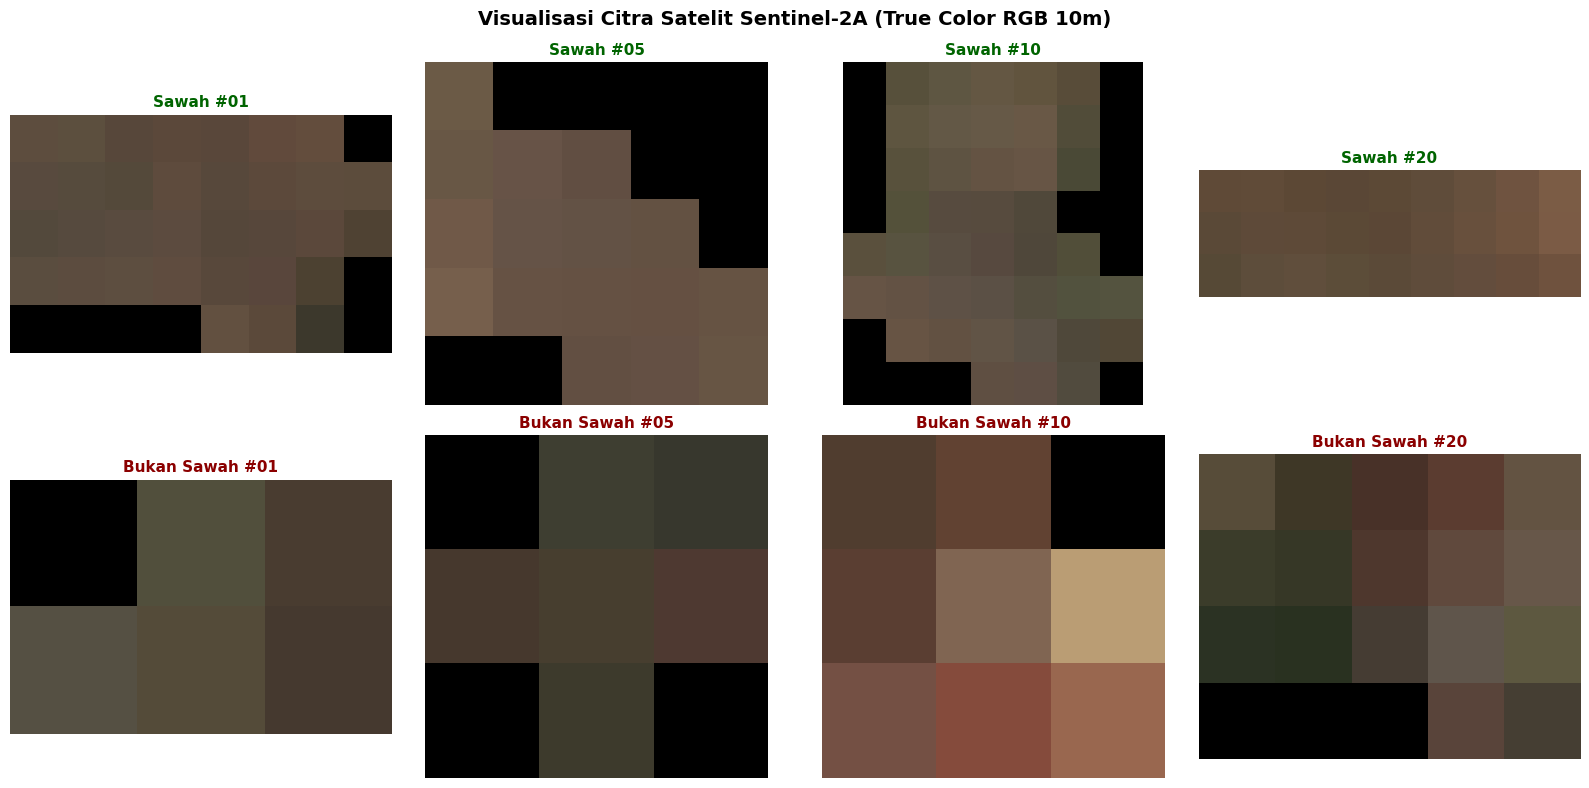

In [6]:
import matplotlib.pyplot as plt

# Visualisasi perbandingan sampel citra Sawah vs Bukan Sawah
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

sample_indices = [1, 5, 10, 20]

for col, idx in enumerate(sample_indices):
    # 1. Citra Sawah (True Color RGB: B04, B03, B02)
    path_sawah = os.path.join(DATA_DIR, "sawah", f"sawah_{idx:02d}.tif")
    with rasterio.open(path_sawah) as src_s:
        img_s = src_s.read([3, 2, 1])  # Red, Green, Blue
        # Normalisasi ke rentang 0-1 untuk visualisasi
        img_s_norm = np.clip(img_s / 3000.0, 0, 1).transpose(1, 2, 0)
        axes[0, col].imshow(img_s_norm)
        axes[0, col].set_title(f"Sawah #{idx:02d}", fontsize=11, fontweight="bold", color="darkgreen")
        axes[0, col].axis("off")

    # 2. Citra Bukan Sawah (True Color RGB: B04, B03, B02)
    path_bukan = os.path.join(DATA_DIR, "bukan_sawah", f"bukan_sawah_{idx:02d}.tif")
    with rasterio.open(path_bukan) as src_b:
        img_b = src_b.read([3, 2, 1])
        img_b_norm = np.clip(img_b / 3000.0, 0, 1).transpose(1, 2, 0)
        axes[1, col].imshow(img_b_norm)
        axes[1, col].set_title(f"Bukan Sawah #{idx:02d}", fontsize=11, fontweight="bold", color="darkred")
        axes[1, col].axis("off")

plt.suptitle("Visualisasi Citra Satelit Sentinel-2A (True Color RGB 10m)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
